# 04 — Prepare SVIR Inputs

**Goal**: Convert the cleaned South Africa series into inputs that can drive or fit the SVIR ODE system.

**Compartments**
- \(S\): Susceptible
- \(V\): Vaccinated (fully vaccinated proxy)
- \(I\): Infectious (undetected)
- \(I_c\): Confirmed infectious
- \(R\): Recovered

**Model reminder**
\[
\begin{aligned}
\frac{dS}{dt} &= \pi + \sigma V - \lambda S - \omega S - \mu S, \\
\frac{dV}{dt} &= \omega S - (1-\epsilon)\lambda V - \sigma V - \mu V, \\
\frac{dI}{dt} &= \lambda S + (1-\epsilon)\lambda V - (\mu + \gamma + \rho_1 + \delta)I, \\
\frac{dI_c}{dt} &= \gamma I - (\mu + \rho_2 + \delta)I_c, \\
\frac{dR}{dt} &= \rho_1 I + \rho_2 I_c - \mu R,
\end{aligned}
\]
with force of infection
\[
\lambda(t) = \frac{\beta\bigl(I(t)+I_c(t)\bigr)}{N(t)}.
\]

**Outputs of this notebook**
- Consistent compartment proxy series
- Initial conditions at a chosen start date
- Fixed / starting parameter dictionary
- Time-varying vaccination rate proxy \(\omega(t)\)
- Clean CSV ready for simulation or parameter estimation


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")


## 1. Load SVIR-ready data

In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# 1. Load your cleaned file
# ------------------------------------------------------------------
DATA = Path("../data/processed/south_africa_cases_vaccination_cleaned.csv")
df = pd.read_csv(DATA, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"Rows: {len(df)}")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"Population N: {df['N'].iloc[0]:,.0f}")

# ------------------------------------------------------------------
# 2. Build SVIR compartment proxies (adapted to your columns)
# ------------------------------------------------------------------
N = float(df["N"].iloc[0])

# Active confirmed proxy (Ic) – rolling sum of daily confirmed cases
INFECTIOUS_DAYS = 10
df["Ic_proxy"] = (
    df["daily_confirmed"]
    .rolling(window=INFECTIOUS_DAYS, min_periods=1)
    .sum()
    .clip(lower=0)
)

# Undetected infectious (I) via constant under-reporting factor
UNDERREPORT = 3.0
df["I_proxy"] = ((UNDERREPORT - 1) * df["Ic_proxy"]).clip(lower=0)

# Vaccinated
df["V_proxy"] = df["V_approx"].clip(lower=0)

# Recovered (already present; recompute for safety)
df["R_proxy"] = (
    df["cumulative_confirmed"] - df["total_deaths"] - df["Ic_proxy"]
).clip(lower=0)

# Disease deaths
df["D_proxy"] = df["total_deaths"]

# Susceptible residual so S + V + I + Ic + R + D = N
df["S_proxy"] = (
    N - df["V_proxy"] - df["I_proxy"] - df["Ic_proxy"] - df["R_proxy"] - df["D_proxy"]
).clip(lower=0)

# Sanity check
df["compartment_sum"] = df[["S_proxy", "V_proxy", "I_proxy", "Ic_proxy", "R_proxy", "D_proxy"]].sum(axis=1)
print("Max |sum - N|:", (df["compartment_sum"] - N).abs().max())

# ------------------------------------------------------------------
# 3. Time-varying vaccination rate proxy ω(t)
# ------------------------------------------------------------------
df["new_fully_vax"] = df["V_proxy"].diff().fillna(0).clip(lower=0)
df["omega_proxy"] = np.where(
    df["S_proxy"] > 1e5,
    df["new_fully_vax"] / df["S_proxy"],
    0.0
)
df["omega_proxy"] = df["omega_proxy"].rolling(7, min_periods=1, center=True).mean().clip(lower=0)

print("Median ω:", df["omega_proxy"].median())

# ------------------------------------------------------------------
# 4. Quick look
# ------------------------------------------------------------------
df[["date", "S_proxy", "V_proxy", "I_proxy", "Ic_proxy", "R_proxy", "daily_confirmed"]].head(10)

Rows: 525
Date range: 2021-02-16 → 2022-07-25
Population N: 59,893,884
Max |sum - N|: 0.0
Median ω: 0.00043392840526088256


,date,S_proxy,V_proxy,I_proxy,Ic_proxy,R_proxy,daily_confirmed
0,2021-02-16,58397345.0,0.0,2420.0,1210.0,1444596.0,1210.0
1,2021-02-17,58390385.0,0.0,7060.0,3530.0,1444431.0,2320.0
2,2021-02-18,58381144.0,2260.0,11714.0,5857.0,1444201.0,2327.0
3,2021-02-19,58371147.0,6524.0,15536.0,7768.0,1444050.0,1911.0
4,2021-02-20,58362187.0,10414.0,18916.0,9458.0,1443969.0,1690.0
5,2021-02-21,58352926.0,15388.0,21774.0,10887.0,1443856.0,1429.0
6,2021-02-22,58342879.0,23059.0,23358.0,11679.0,1443759.0,792.0
7,2021-02-23,58330629.0,32315.0,25354.0,12677.0,1443496.0,998.0
8,2021-02-24,58315549.0,41809.0,29078.0,14539.0,1443386.0,1862.0
9,2021-02-25,58299683.0,52647.0,32430.0,16215.0,1443242.0,1676.0


In [12]:
# Choose a start date inside your series (default = first day)
START = pd.Timestamp("2021-02-16")
row0 = df.loc[df["date"] >= START].iloc[0]

initial_conditions = {
    "date": str(row0["date"].date()),
    "S0": float(row0["S_proxy"]),
    "V0": float(row0["V_proxy"]),
    "I0": float(row0["I_proxy"]),
    "Ic0": float(row0["Ic_proxy"]),
    "R0": float(row0["R_proxy"]),
    "N0": N,
}

print("Initial conditions:")
for k, v in initial_conditions.items():
    if isinstance(v, float):
        print(f"  {k}: {v:,.1f}")
    else:
        print(f"  {k}: {v}")

Initial conditions:
  date: 2021-02-16
  S0: 58,397,345.0
  V0: 0.0
  I0: 2,420.0
  Ic0: 1,210.0
  R0: 1,444,596.0
  N0: 59,893,884.0


In [13]:
# South Africa demographic rates (keeps N roughly constant)
mu = 9.5 / 1000 / 365          # day^{-1}
pi = mu * N                    # individuals / day

params = {
    # Demographic
    "pi": pi,
    "mu": mu,
    # Vaccination
    "omega": 0.001,            # constant fallback; prefer omega_proxy(t)
    "sigma": 1 / 180,          # vaccine waning ~6 months
    "epsilon": 0.65,           # efficacy against infection
    # Natural history
    "gamma": 1 / 5,            # detection rate I → Ic
    "rho1": 1 / 10,            # recovery of undetected
    "rho2": 1 / 12,            # recovery of confirmed
    "delta": 0.001,            # disease-induced death rate
    # Transmission (placeholder – to be estimated later)
    "beta": 0.25,
}

print("Parameter starting values:")
for k, v in params.items():
    print(f"  {k:8s} = {v:.6g}")

Parameter starting values:
  pi       = 1558.88
  mu       = 2.60274e-05
  omega    = 0.001
  sigma    = 0.00555556
  epsilon  = 0.65
  gamma    = 0.2
  rho1     = 0.1
  rho2     = 0.0833333
  delta    = 0.001
  beta     = 0.25


In [14]:
keep = [
    "date", "N",
    "S_proxy", "V_proxy", "I_proxy", "Ic_proxy", "R_proxy", "D_proxy",
    "daily_confirmed", "cumulative_confirmed", "total_deaths",
    "omega_proxy", "new_fully_vax",
    "full_vax_coverage", "partial_vax_coverage",
]

svir_inputs = df[keep].copy()
svir_inputs = svir_inputs.rename(columns={
    "S_proxy": "S",
    "V_proxy": "V",
    "I_proxy": "I",
    "Ic_proxy": "Ic",
    "R_proxy": "R",
    "D_proxy": "D",
    "daily_confirmed": "y_daily_confirmed",
    "total_deaths": "D_cumulative",
})

out_path = Path("../data/processed/south_africa_svir_inputs.csv")
svir_inputs.to_csv(out_path, index=False)
print(f"Saved → {out_path}")
print(f"Shape: {svir_inputs.shape}")
svir_inputs.head()

Saved → ..\data\processed\south_africa_svir_inputs.csv
Shape: (525, 15)


,date,N,S,V,I,Ic,R,D,y_daily_confirmed,cumulative_confirmed,D_cumulative,omega_proxy,new_fully_vax,full_vax_coverage,partial_vax_coverage
0,2021-02-16,59893884,58397345.0,0.0,2420.0,1210.0,1444596.0,48313.0,1210.0,1494119.0,48313.0,0.000028,0.0,0.000000,0.000000
1,2021-02-17,59893884,58390385.0,0.0,7060.0,3530.0,1444431.0,48478.0,2320.0,1496439.0,48478.0,0.000036,0.0,0.000000,0.000000
2,2021-02-18,59893884,58381144.0,2260.0,11714.0,5857.0,1444201.0,48708.0,2327.0,1498766.0,48708.0,0.000044,2260.0,0.000038,0.000038
3,2021-02-19,59893884,58371147.0,6524.0,15536.0,7768.0,1444050.0,48859.0,1911.0,1500677.0,48859.0,0.000056,4264.0,0.000109,0.000109
4,2021-02-20,59893884,58362187.0,10414.0,18916.0,9458.0,1443969.0,48940.0,1690.0,1502367.0,48940.0,0.000079,3890.0,0.000174,0.000174


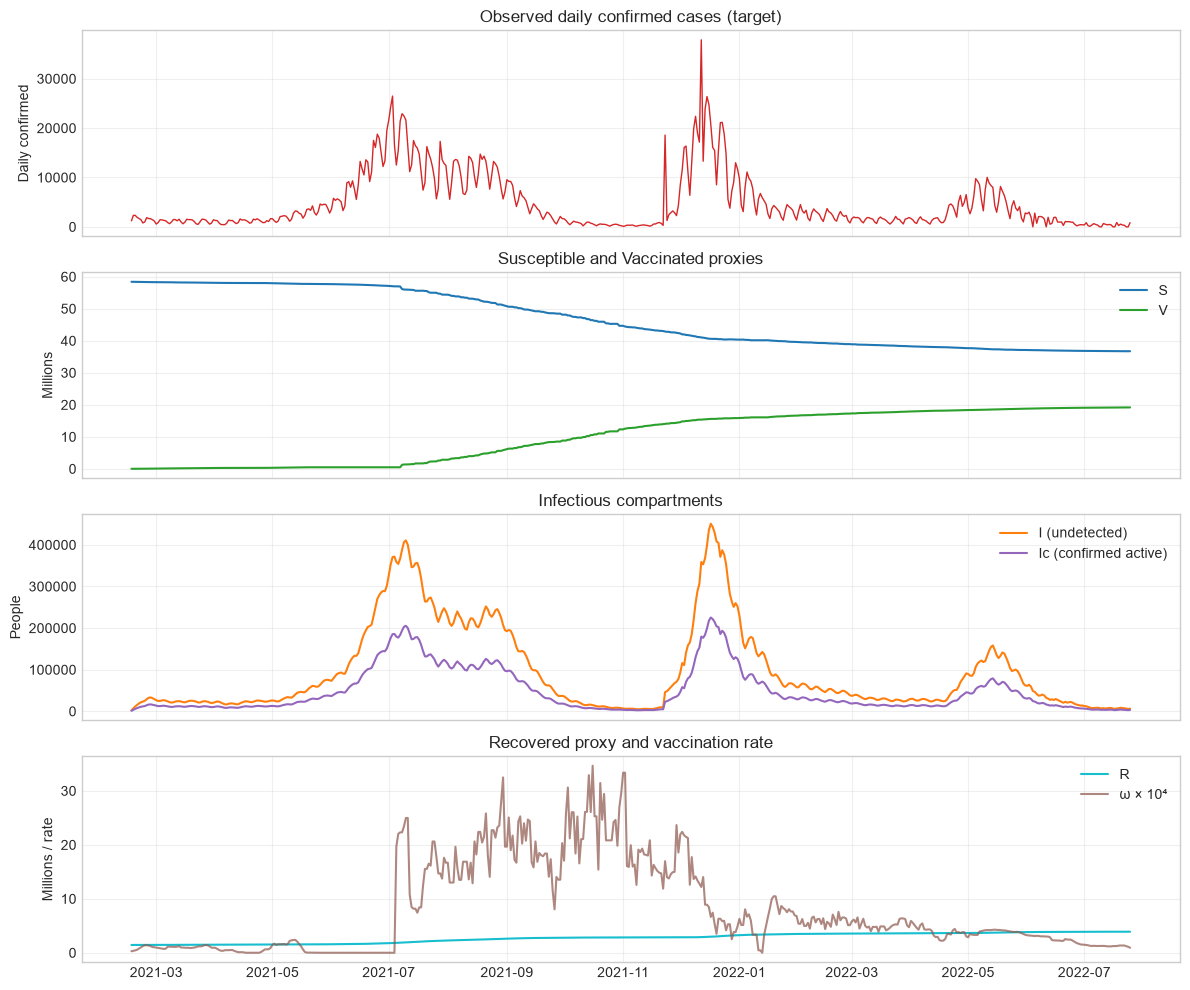

In [15]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)

axes[0].plot(svir_inputs["date"], svir_inputs["y_daily_confirmed"], color="tab:red", lw=1)
axes[0].set_ylabel("Daily confirmed")
axes[0].set_title("Observed daily confirmed cases (target)")

axes[1].plot(svir_inputs["date"], svir_inputs["S"] / 1e6, label="S", color="tab:blue")
axes[1].plot(svir_inputs["date"], svir_inputs["V"] / 1e6, label="V", color="tab:green")
axes[1].set_ylabel("Millions")
axes[1].legend()
axes[1].set_title("Susceptible and Vaccinated proxies")

axes[2].plot(svir_inputs["date"], svir_inputs["I"], label="I (undetected)", color="tab:orange")
axes[2].plot(svir_inputs["date"], svir_inputs["Ic"], label="Ic (confirmed active)", color="tab:purple")
axes[2].set_ylabel("People")
axes[2].legend()
axes[2].set_title("Infectious compartments")

axes[3].plot(svir_inputs["date"], svir_inputs["R"] / 1e6, label="R", color="tab:cyan")
axes[3].plot(svir_inputs["date"], svir_inputs["omega_proxy"] * 1e4, label="ω × 10⁴", color="tab:brown", alpha=0.7)
axes[3].set_ylabel("Millions / rate")
axes[3].legend()
axes[3].set_title("Recovered proxy and vaccination rate")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()